# FlowLens Gate 4｜策略实验室与决策闭环

## tl;dr

- S0–S4 五个策略均先在验证集选参，再冻结到标准曝光与随机曝光日志回放；测试候选范围完全一致。
- 标准曝光测试上，S2 的 NDCG@5 点估计最高（**0.6241**，相对 S0 **+0.0005**），Top-5 ECR 为 **45.99%**（**+0.06 个百分点**）。
- S2 将作者重复率从 **0.36%** 降至 **0.31%**，主标签重复率从 **31.39%** 降至 **29.74%**，但内容覆盖从 **88.49%** 降至 **87.54%**。
- S1–S4 的 NDCG 与 ECR 增量区间均跨 0，因此全部判为 **ITERATE_AND_RETEST**；本轮没有策略通过线上 A/B 准入门槛。
- 随机曝光敏感性上 S2 的 NDCG@5 相对 S0 为 **+0.0221**，但采集策略分布显著漂移，该结果只用于稳健性诊断。

> 证据边界：这是公开日志上的 E3 retrospective replay，不是真实平台的线上实验、上线收益或商业影响。

## Context & Methods

Gate 4 把 Gate 3 的诊断转为可配置策略和明确决策规则，形成“假设—配置—验证—取舍—实验设计”闭环，而不是追求一个看起来更高的单指标。

### Key assumptions

- S0 为冻结的 MultiTaskHashSGD 基线；S1 融合 ItemCF，S2 加入作者／标签多样性，S3 加入长尾探索，S4 加入历史负反馈与作者疲劳控制。
- 所有权重只在 2022-04-18 至 04-21 的验证集选择；2022-04-22 至 05-08 的两个测试日志不参与调参。
- 策略只使用请求前可得字段；测试窗的点击、长播和负反馈只用于评估。
- S3 使用历史长尾代理，不宣称验证了新内容冷启动。
- `ENTER_ONLINE_AB_CANDIDATE` 只表示可进入未来随机实验，不代表允许上线。

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd if (cwd / "reports" / "gate4").exists() else cwd.parent
REPORT_DIR = PROJECT_ROOT / "reports" / "gate4"

metrics = pd.read_csv(REPORT_DIR / "strategy_metrics.csv")
deltas = pd.read_csv(REPORT_DIR / "strategy_deltas.csv")
decisions = pd.read_csv(REPORT_DIR / "offline_decisions.csv")
selection = pd.read_csv(REPORT_DIR / "validation_selection.csv")
snapshots = json.loads((REPORT_DIR / "strategy_snapshots.json").read_text(encoding="utf-8"))
suite = json.loads((REPORT_DIR / "evaluation_tests.json").read_text(encoding="utf-8"))
validation = json.loads((REPORT_DIR / "validation_summary.json").read_text(encoding="utf-8"))
run = json.loads((REPORT_DIR / "run_manifest.json").read_text(encoding="utf-8"))

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.figsize": (9.5, 5.2), "axes.titlesize": 13, "axes.labelsize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "axes.edgecolor": "#334155",
    "text.color": "#172033", "axes.labelcolor": "#172033",
})
COLORS = {"S0": "#8B95A5", "S1": "#2457A6", "S2": "#D6A328", "S3": "#7C8E42", "S4": "#C04B76"}

## Data and integrity gates

本 Notebook 只读取 Gate 4 的紧凑产物，不重复加载大体积行级日志。逐用户指标、配对差值、验证集 argmax、策略快照、代码／配置哈希和上游 Gate 3 血缘由独立脚本复核。

In [2]:
assert run["status"] == "VALID"
assert run["evidence_level"] == "E3"
assert validation["status"] == "PASS"
assert len(validation["checks"]) == 15
assert all(item["status"] == "PASS" for item in validation["checks"])
assert set(decisions["decision"]) == {"BASELINE", "ITERATE_AND_RETEST"}

display(pd.DataFrame(validation["checks"]))
display(pd.DataFrame([
    {"strategy": key, "name": value["name"], "parameters": value["parameters"], "snapshot": value["snapshot_sha256"][:12]}
    for key, value in snapshots.items()
]))

,check,status,detail
0,required_artifacts_exist,PASS,missing=[]
1,manifest_hashes_match_current_code,PASS,"script_match=True, config_match=True"
2,upstream_gate3_lineage_matches,PASS,gate3_run_id=gate3-3b42b7057a17
3,strategy_split_matrix_complete,PASS,"rows=15, pairs=15"
4,identical_candidates_within_split,PASS,candidate counts are identical across S0-S4
5,user_metrics_recompute,PASS,maximum_absolute_difference=1.110e-16
6,paired_deltas_recompute,PASS,maximum_absolute_difference=9.845e-17
7,validation_selection_is_argmax,PASS,one validation argmax selected per strategy
8,strategy_snapshots_are_immutable,PASS,snapshots=5
9,forbidden_outcomes_not_scoring_features,PASS,overlap=[]


,strategy,name,parameters,snapshot
0,S0,MultiTask baseline,{},44136fa355b3
1,S1,Collaborative blend,{'itemcf_weight': 0.15},340c86d91574
2,S2,Diversity rerank,"{'itemcf_weight': 0.15, 'author_repeat_penalty...",21eea195e58a
3,S3,Long-tail exploration,"{'itemcf_weight': 0.15, 'author_repeat_penalty...",a37b24b5f473
4,S4,Negative-feedback and fatigue control,"{'itemcf_weight': 0.15, 'author_repeat_penalty...",af95adfcd63e


## Results

### 1. 标准曝光增量均存在统计不确定性

下面的区间来自用户级配对 bootstrap。所有 challenger 的 NDCG 与 ECR 点估计略高于 S0，但区间跨 0；这正是“看起来提升”和“足以做决策”的区别。

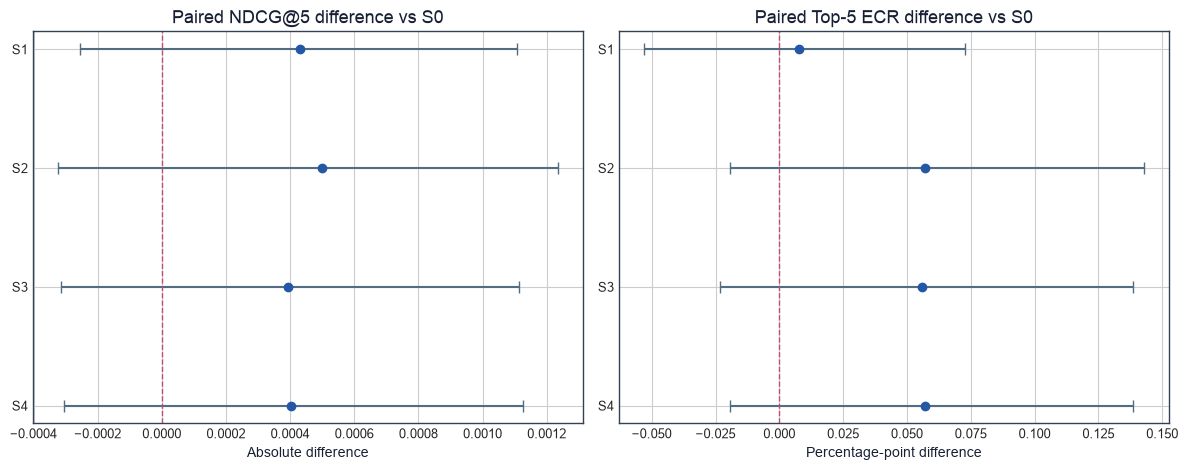

,strategy,paired_users,ndcg_at_5_delta,ndcg_at_5_delta_ci_low,ndcg_at_5_delta_ci_high,ecr_at_5_delta,ecr_at_5_delta_ci_low,ecr_at_5_delta_ci_high
1,S1,20741,0.000430,-0.000254,0.001108,0.000077,-0.000531,0.000728
2,S2,20741,0.000499,-0.000324,0.001235,0.000569,-0.000194,0.001429
3,S3,20741,0.000394,-0.000314,0.001113,0.000559,-0.000233,0.001384
4,S4,20741,0.000404,-0.000305,0.001125,0.000569,-0.000193,0.001384


In [3]:
standard_delta = deltas[(deltas["split"] == "standard_test") & (deltas["strategy"] != "S0")].copy()
strategies = standard_delta["strategy"].tolist()
y = np.arange(len(strategies))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

for ax, metric, title, scale, label in [
    (axes[0], "ndcg_at_5", "Paired NDCG@5 difference vs S0", 1.0, "Absolute difference"),
    (axes[1], "ecr_at_5", "Paired Top-5 ECR difference vs S0", 100.0, "Percentage-point difference"),
]:
    center = standard_delta[f"{metric}_delta"].to_numpy() * scale
    low = standard_delta[f"{metric}_delta_ci_low"].to_numpy() * scale
    high = standard_delta[f"{metric}_delta_ci_high"].to_numpy() * scale
    ax.errorbar(center, y, xerr=[center - low, high - center], fmt="o", color="#2457A6", ecolor="#526D82", capsize=4)
    ax.axvline(0, color="#C04B76", lw=1, linestyle="--")
    ax.set_yticks(y, strategies)
    ax.set_title(title)
    ax.set_xlabel(label)
    ax.invert_yaxis()
fig.tight_layout()
plt.show()

display(standard_delta[[
    "strategy", "paired_users", "ndcg_at_5_delta", "ndcg_at_5_delta_ci_low", "ndcg_at_5_delta_ci_high",
    "ecr_at_5_delta", "ecr_at_5_delta_ci_low", "ecr_at_5_delta_ci_high",
]])

### 2. S2 展示了效率与生态护栏的真实取舍

S2 改善了作者和主标签重复，但内容覆盖略降，负反馈点估计没有改善。它是下一轮优先迭代对象，而不是当前可直接进入线上实验的“赢家”。

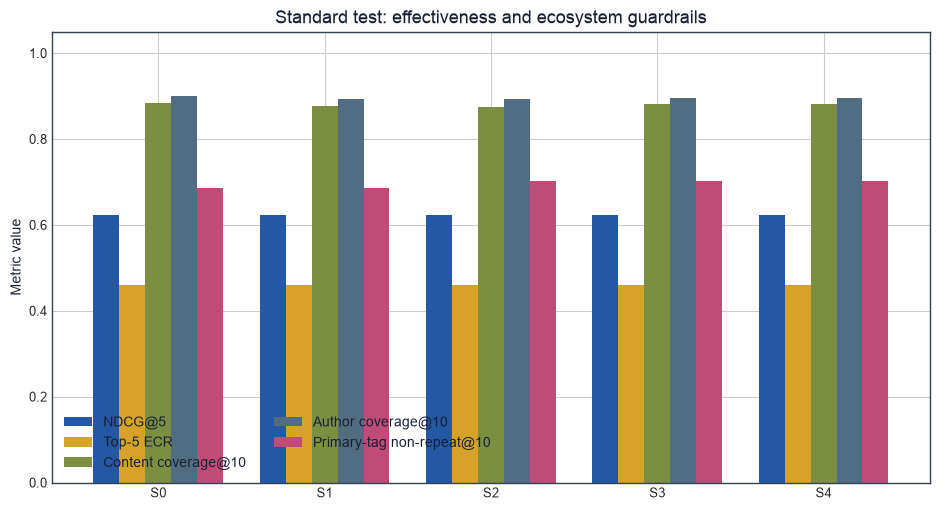

,metric,S0,S2,delta
0,NDCG@5,0.623576,0.624075,0.000499
1,Top-5 ECR,0.459287,0.459856,0.000569
2,Content coverage@10,0.884869,0.875364,-0.009505
3,Author repeat@10,0.003614,0.003098,-0.000516
4,Primary-tag repeat@10,0.313898,0.297394,-0.016504


In [4]:
standard = metrics[metrics["split"] == "standard_test"].set_index("strategy")
comparison = pd.DataFrame({
    "NDCG@5": standard["ndcg_at_5"],
    "Top-5 ECR": standard["ecr_at_5"],
    "Content coverage@10": standard["content_coverage_at_10"],
    "Author coverage@10": standard["author_coverage_at_10"],
    "Primary-tag non-repeat@10": 1 - standard["primary_tag_repeat_rate_at_10"],
})
ax = comparison.plot.bar(color=["#2457A6", "#D6A328", "#7C8E42", "#526D82", "#C04B76"], width=0.78)
ax.set_title("Standard test: effectiveness and ecosystem guardrails")
ax.set_ylabel("Metric value")
ax.set_xlabel("")
ax.set_xticklabels(comparison.index, rotation=0)
ax.set_ylim(0, 1.05)
ax.legend(frameon=False, ncol=2, loc="lower left")
plt.tight_layout()
plt.show()

s0 = standard.loc["S0"]
s2 = standard.loc["S2"]
tradeoff = pd.DataFrame([
    {"metric": "NDCG@5", "S0": s0["ndcg_at_5"], "S2": s2["ndcg_at_5"], "delta": s2["ndcg_at_5"] - s0["ndcg_at_5"]},
    {"metric": "Top-5 ECR", "S0": s0["ecr_at_5"], "S2": s2["ecr_at_5"], "delta": s2["ecr_at_5"] - s0["ecr_at_5"]},
    {"metric": "Content coverage@10", "S0": s0["content_coverage_at_10"], "S2": s2["content_coverage_at_10"], "delta": s2["content_coverage_at_10"] - s0["content_coverage_at_10"]},
    {"metric": "Author repeat@10", "S0": s0["author_repeat_rate_at_10"], "S2": s2["author_repeat_rate_at_10"], "delta": s2["author_repeat_rate_at_10"] - s0["author_repeat_rate_at_10"]},
    {"metric": "Primary-tag repeat@10", "S0": s0["primary_tag_repeat_rate_at_10"], "S2": s2["primary_tag_repeat_rate_at_10"], "delta": s2["primary_tag_repeat_rate_at_10"] - s0["primary_tag_repeat_rate_at_10"]},
])
display(tradeoff)

### 3. 随机曝光支持方向性，但不能替代线上实验

随机曝光敏感性中，S1–S4 均高于 S0，S2 的 NDCG@5 增量最大。但标准与随机日志的标签率和分数分布显著不同，不能把该差值当作 treatment effect。

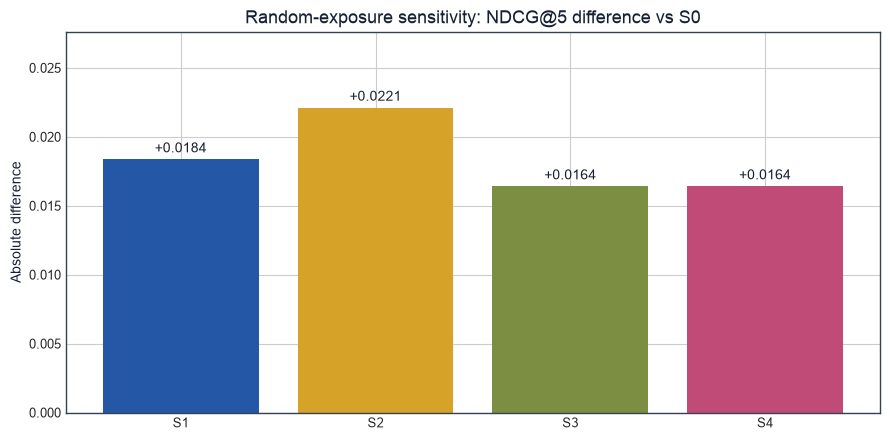

,status,standard_long_view_rate,random_long_view_rate,multitask_score_ks_statistic,multitask_score_ks_pvalue,interpretation
0,WARN,0.321205,0.084965,0.115852,0.0,Collection-policy shift is material; random ex...


In [5]:
random_delta = deltas[deltas["split"] == "random_sensitivity"].set_index("strategy").loc[["S1", "S2", "S3", "S4"]]
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(random_delta.index, random_delta["ndcg_at_5_delta"], color=[COLORS[key] for key in random_delta.index])
ax.set_title("Random-exposure sensitivity: NDCG@5 difference vs S0")
ax.set_ylabel("Absolute difference")
ax.set_xlabel("")
ax.bar_label(bars, labels=[f"{value:+.4f}" for value in random_delta["ndcg_at_5_delta"]], padding=3)
ax.set_ylim(0, random_delta["ndcg_at_5_delta"].max() * 1.25)
plt.tight_layout()
plt.show()

display(pd.DataFrame([suite["distribution_shift"]]))

### 4. 决策规则阻止“点估计好看就上线”

每个 challenger 必须同时通过 NDCG、ECR、内容覆盖、作者覆盖、作者重复和随机曝光敏感性六项规则。本轮四个 challenger 都只通过 4/6。

In [6]:
decision_view = decisions.merge(
    metrics[metrics["split"] == "standard_test"][["strategy", "ndcg_at_5", "ecr_at_5", "content_coverage_at_10", "author_repeat_rate_at_10"]],
    on="strategy",
)
display(decision_view)

selected_variants = selection[selection["selected"]].copy()
display(selected_variants[["strategy", "variant", "objective", "parameters"]])

,strategy,decision,passed_rules,total_rules,reason,ndcg_at_5,ecr_at_5,content_coverage_at_10,author_repeat_rate_at_10
0,S0,BASELINE,0,0,Frozen comparison baseline.,0.623576,0.459287,0.884869,0.003614
1,S1,ITERATE_AND_RETEST,4,6,"Failed: ndcg_ci, ecr_ci",0.624006,0.459364,0.877664,0.003580
2,S2,ITERATE_AND_RETEST,4,6,"Failed: ndcg_ci, ecr_ci",0.624075,0.459856,0.875364,0.003098
3,S3,ITERATE_AND_RETEST,4,6,"Failed: ndcg_ci, ecr_ci",0.623970,0.459846,0.880576,0.003108
4,S4,ITERATE_AND_RETEST,4,6,"Failed: ndcg_ci, ecr_ci",0.623980,0.459856,0.880576,0.003108


,strategy,variant,objective,parameters
0,S0,1,0.700593,{}
1,S1,1,0.700238,"{""itemcf_weight"": 0.15}"
7,S2,4,0.700284,"{""author_repeat_penalty"": 0.06, ""itemcf_weight..."
10,S3,3,0.700535,"{""author_repeat_penalty"": 0.06, ""itemcf_weight..."
13,S4,3,0.700534,"{""author_repeat_penalty"": 0.06, ""fatigue_penal..."


## Takeaways

1. **Gate 4 的价值是做出“不进入 A/B”的可信判断。** 四个 challenger 点估计为正，但不确定性不足，全部需要迭代重测。
2. **S2 是优先迭代方向。** 它兼顾最高的标准测试 NDCG 点估计、较低作者重复与较低标签重复；下一轮应减少内容覆盖损失并扩大可识别差异。
3. **S4 的机制尚未被验证。** 历史负反馈非常稀疏，S4 没有在标准曝光上明显降低观察到的 hate rate；不能因为“加入了负反馈特征”就宣称体验改善。
4. **双日志结果必须同时保留。** 随机曝光对策略方向更乐观，但分布漂移明确，因此只能作为敏感性证据。
5. **线上实验仍是必经门槛。** 当前没有真实 MDE、样本量、SRM、A/A 或触发数据；实验设计书只定义合同与阻断规则，不伪造执行结果。